# Four-method regional MD profile comparison

This notebook reads Python-generated summaries for Native, FS DepthMap, Profile Interp., and Coordinate Interp. on fsaverage. It performs no expensive profile generation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

OUTPUT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/"
    "method_comparison_regional_profiles_fsaverage_common30"
)
profiles = pd.read_csv(OUTPUT_ROOT / "regional_profiles_long.csv")
qc = pd.read_csv(OUTPUT_ROOT / "regional_profile_qc.csv")
metrics = pd.read_csv(OUTPUT_ROOT / "regional_method_metrics.csv")
summary = pd.read_csv(OUTPUT_ROOT / "regional_method_summary.csv")
depth_summary = pd.read_csv(
    OUTPUT_ROOT / "regional_depthwise_method_summary.csv"
)
print("Subjects:", profiles.subject_id.nunique())
print("Regions per hemisphere:", profiles.region.nunique())
print("Methods:", sorted(profiles.method.unique()))

Subjects: 30
Regions per hemisphere: 34
Methods: ['Coordinate Interp.', 'FS DepthMap', 'Native', 'Profile Interp.']


In [2]:
qc_summary = (
    qc.groupby(["method", "status"], as_index=False)
    .size()
    .rename(columns={"size": "n_region_units"})
)
display(qc_summary)
display(
    summary[
        [
            "method_a",
            "method_b",
            "region",
            "n_subjects",
            "pearson_median",
            "mae_median",
            "sNMAE_pct_median",
        ]
    ].head(20)
)

,method,status,n_region_units
0,Coordinate Interp.,complete,2040
1,FS DepthMap,complete,2040
2,Native,complete,2040
3,Profile Interp.,complete,2040


,method_a,method_b,region,n_subjects,pearson_median,mae_median,sNMAE_pct_median
0,Coordinate Interp.,Native,bankssts,30,0.999515,0.000008,1.047943
1,Coordinate Interp.,Native,caudalanteriorcingulate,30,0.997995,0.000011,1.449934
2,Coordinate Interp.,Native,caudalmiddlefrontal,30,0.999795,0.000007,0.890899
3,Coordinate Interp.,Native,cuneus,30,0.999877,0.000013,1.572598
4,Coordinate Interp.,Native,entorhinal,30,0.993511,0.000019,2.689867
5,Coordinate Interp.,Native,frontalpole,30,0.996671,0.000039,4.757377
6,Coordinate Interp.,Native,fusiform,30,0.999761,0.000006,0.957556
7,Coordinate Interp.,Native,inferiorparietal,30,0.999856,0.000005,0.649518
8,Coordinate Interp.,Native,inferiortemporal,30,0.999176,0.000008,1.175126
9,Coordinate Interp.,Native,insula,30,0.999613,0.000016,2.139218


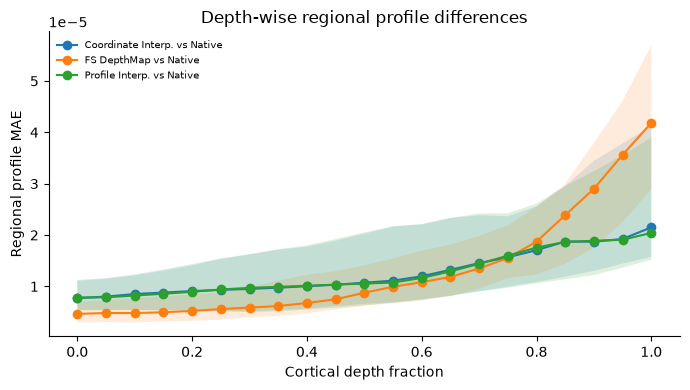

In [3]:
pair_labels = {
    ("FS DepthMap", "Native"): "FS DepthMap vs Native",
    ("Profile Interp.", "Native"): "Profile Interp. vs Native",
    ("Coordinate Interp.", "Native"): "Coordinate Interp. vs Native",
    ("Coordinate Interp.", "Profile Interp."): "Coordinate Interp. vs Profile Interp.",
}
plot_data = depth_summary[
    depth_summary.method_b.eq("Native")
].copy()
plot_data["comparison"] = [
    pair_labels[(a, b)]
    for a, b in zip(plot_data.method_a, plot_data.method_b)
]
depth_plot = (
    plot_data.groupby(["comparison", "depth_fraction"], as_index=False)
    .agg(mae_median=("mae", "median"),
         mae_q25=("mae", lambda x: x.quantile(0.25)),
         mae_q75=("mae", lambda x: x.quantile(0.75)))
)
fig, ax = plt.subplots(figsize=(7, 4))
for comparison, group in depth_plot.groupby("comparison"):
    group = group.sort_values("depth_fraction")
    ax.plot(group.depth_fraction, group.mae_median, marker="o", label=comparison)
    ax.fill_between(
        group.depth_fraction,
        group.mae_q25,
        group.mae_q75,
        alpha=0.15,
    )
ax.set_xlabel("Cortical depth fraction")
ax.set_ylabel("Regional profile MAE")
ax.set_title("Depth-wise regional profile differences")
ax.legend(frameon=False, fontsize=7)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

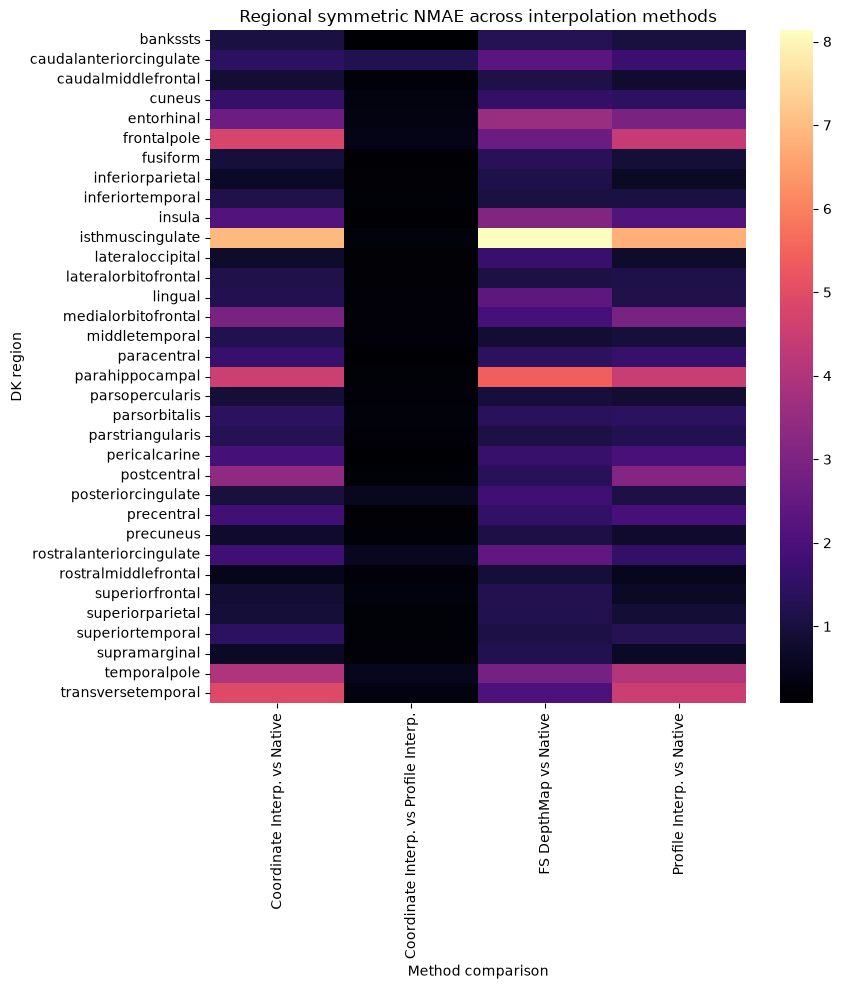

In [4]:
heatmap = summary.copy()
heatmap["comparison"] = [
    pair_labels[(a, b)]
    for a, b in zip(heatmap.method_a, heatmap.method_b)
]
heatmap = heatmap.pivot(
    index="region",
    columns="comparison",
    values="sNMAE_pct_median",
)
fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(heatmap, cmap="magma", annot=False, ax=ax)
ax.set_title("Regional symmetric NMAE across interpolation methods")
ax.set_xlabel("Method comparison")
ax.set_ylabel("DK region")
fig.tight_layout()
plt.show()

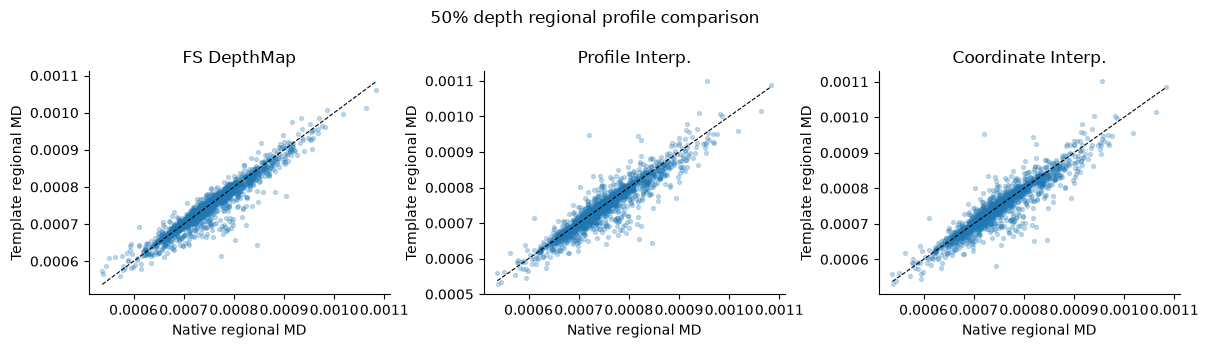

In [5]:
depth_50 = profiles[profiles.depth_fraction.eq(0.5)].copy()
depth_50 = depth_50.pivot_table(
    index=["subject_id", "hemisphere", "region"],
    columns="method",
    values="profile_value",
    aggfunc="first",
).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, method in zip(
    axes,
    ["FS DepthMap", "Profile Interp.", "Coordinate Interp."],
):
    ax.scatter(
        depth_50["Native"],
        depth_50[method],
        s=8,
        alpha=0.25,
    )
    limits = [
        depth_50["Native"].min(),
        depth_50["Native"].max(),
    ]
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(method)
    ax.set_xlabel("Native regional MD")
    ax.set_ylabel("Template regional MD")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("50% depth regional profile comparison")
fig.tight_layout()
plt.show()